# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import FireRiskDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

New train/val/test split

In [ ]:
dataset_config = {
    "data_dir": "./data/FireRisk/train/",
    "csv_file": "./data/FireRisk/splits_final/firerisk_train.csv"
}
dataset = FireRiskDataset(dataset_config)
print(len(dataset))

55123


Original train/test split

In [ ]:
dataset_config = {
    "data_dir": "./data/FireRisk/train/",
}
dataset = FireRiskDataset(dataset_config)
print(len(dataset))

70331


## Show images from the dataset

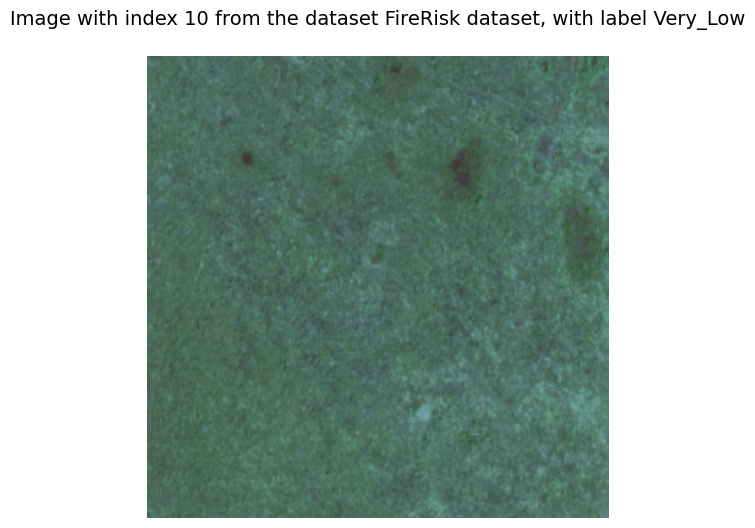

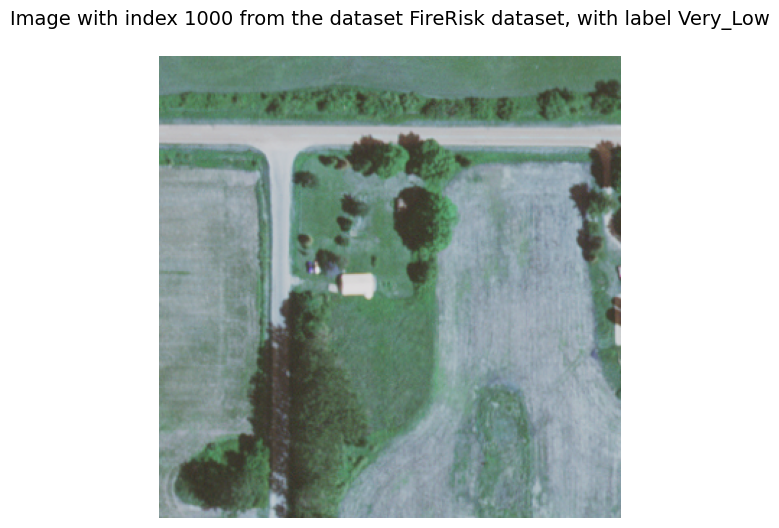

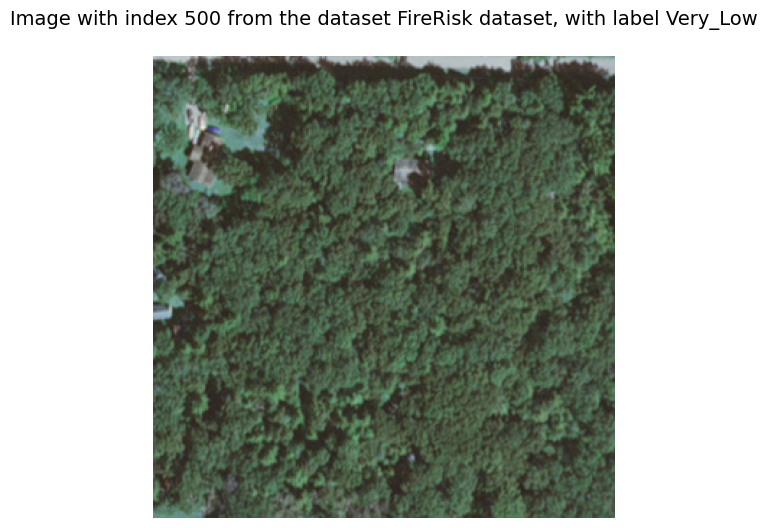

In [10]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(1000)
fig3 = dataset.show_image(500)

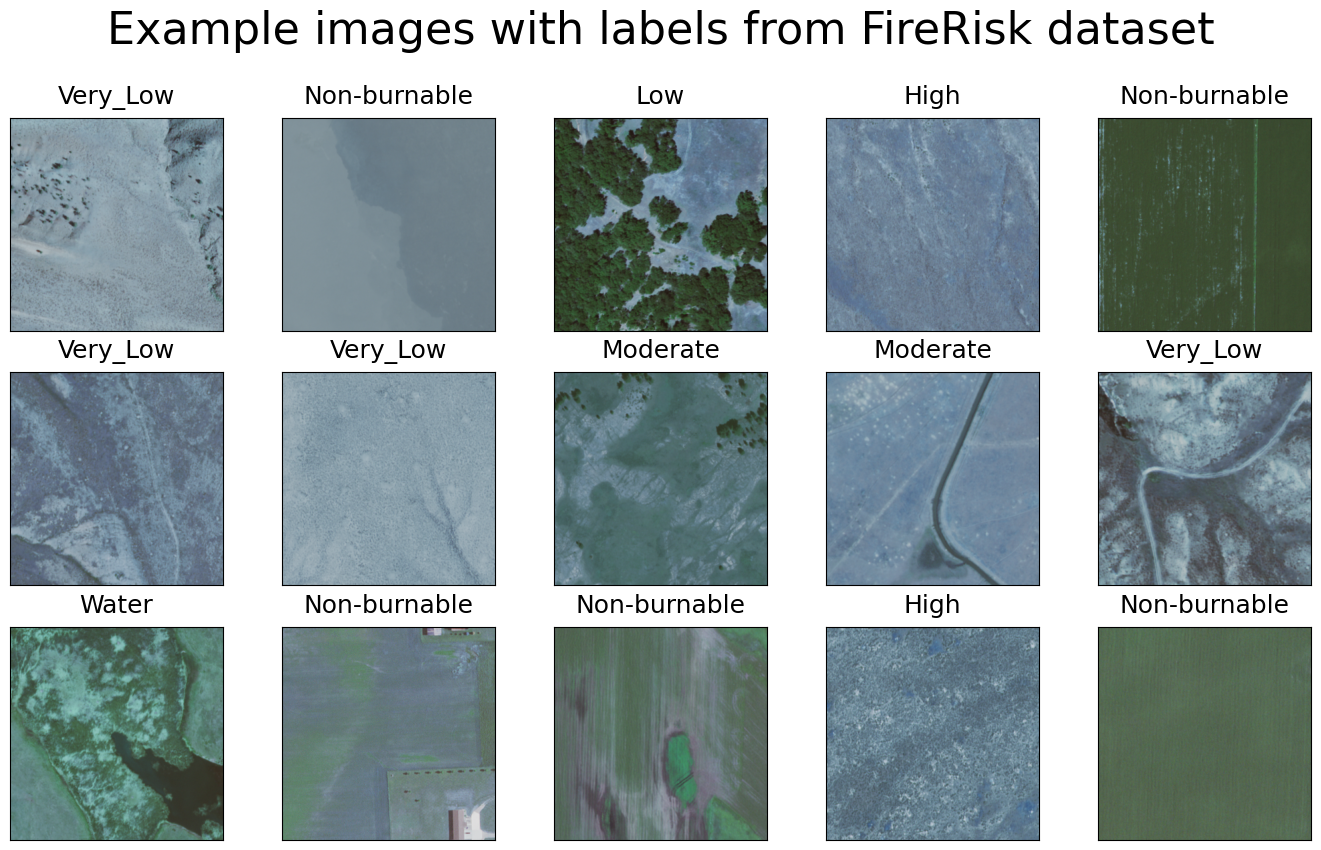

In [9]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [14]:
dataset.data_distribution_table()

,Label,Count
0,High,6296
1,Low,10705
2,Moderate,8617
3,Non-burnable,17959
4,Very_High,3268
5,Very_Low,21757
6,Water,1729


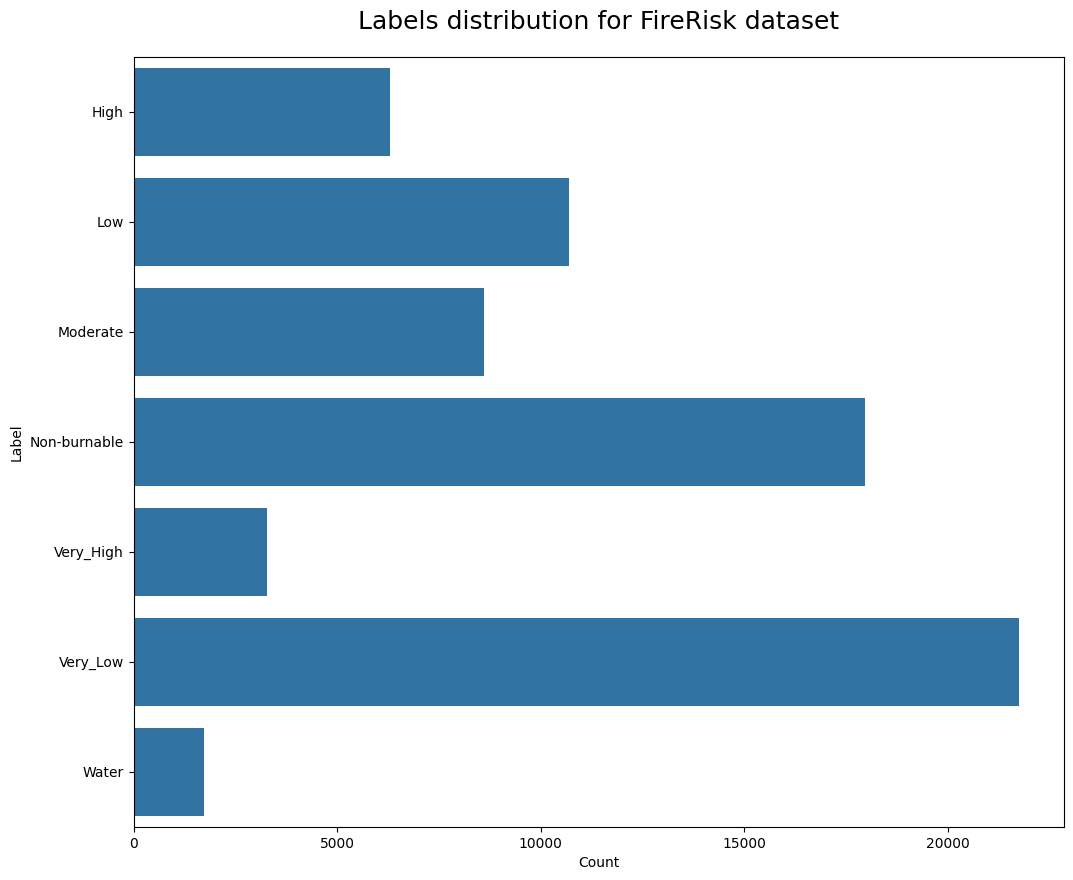

In [15]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/FireRisk/train/",
}

train_dataset = FireRiskDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/FireRisk/val/",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = FireRiskDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(70331, 21541)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/FireRisk/"
model_config = {
    "num_classes": 7, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-28 12:56:13,003 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-28 12:56:13,190 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [6]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-28 12:56:14,718 INFO Starting training.
training: 100%|██████████| 2198/2198 [19:36<00:00,  1.87it/s]
2025-05-28 13:15:51,975 INFO epoch: 1, time: 1177, loss:  1.13881
testing on train set: 100%|██████████| 2198/2198 [06:48<00:00,  5.38it/s]
2025-05-28 13:22:42,593 INFO Accuracy:0.5713554478110648, Precision Micro:0.5713554478110648, Precision Macro:0.5508944927456885, Precision Weighted:0.5518856471487266, Precision per Class:[0.34683191 0.40787802 0.39322336 0.77685739 0.434644   0.54505013
 0.95177665], Recall Micro:0.5713554478110648, Recall Macro:0.4696204770810707, Recall Weighted:0.571355447811065, Recall per Class:[0.63119441 0.02998599 0.20471162 0.84598252 0.125153   0.79965069
 0.65066512], F1_score Micro:0.5713554478110643, F1_score Macro:0.4568944789918829, F1_score Weighted:0.5169558876223712, F1_score per Class:[0.44767376 0.05586495 0.26925132 0.80994776 0.19434545 0.64824785
 0.77293026]
testing on validation set: 100%|██████████| 674/674 [02:06<00:00,  5.34it/

0.880819861833392

## Predictions

2025-05-29 06:39:58,882 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/FireRisk/checkpoint.pth.tar
2025-05-29 06:39:59,100 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/FireRisk/checkpoint.pth.tar at epoch 11


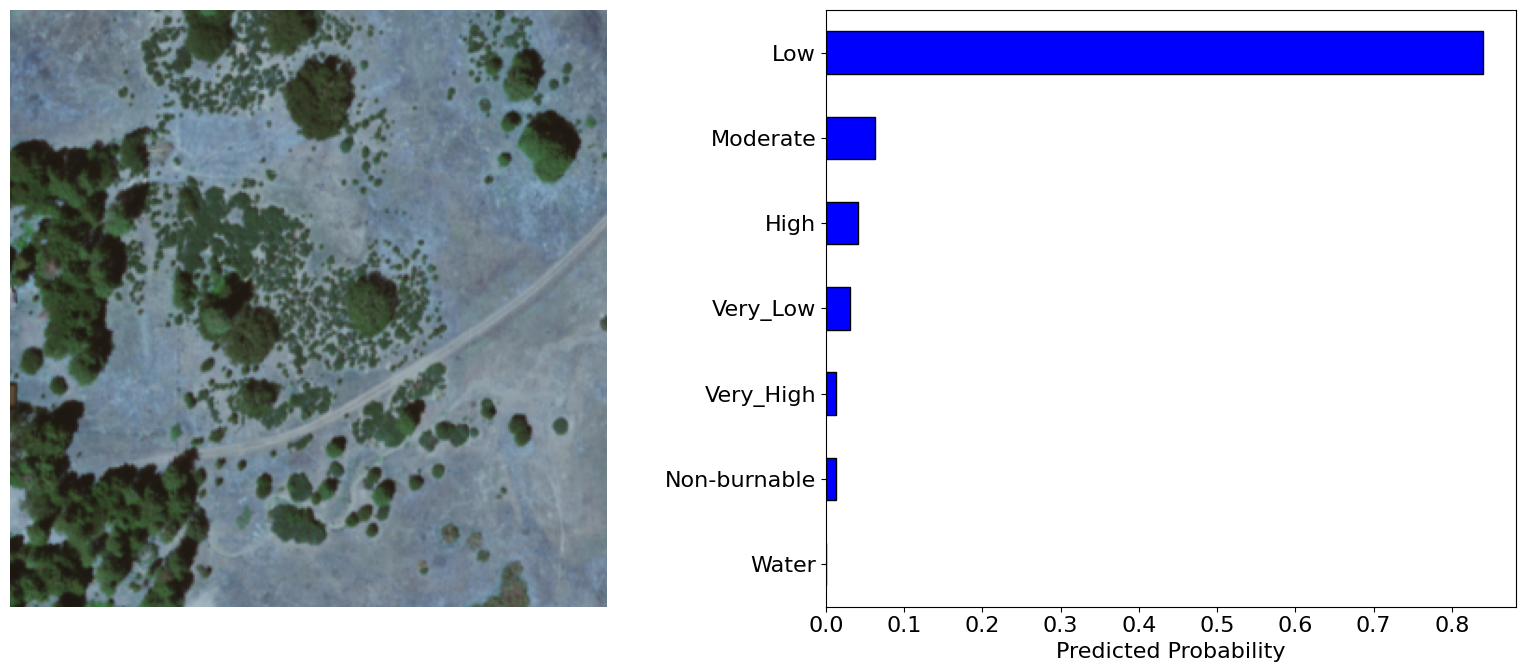

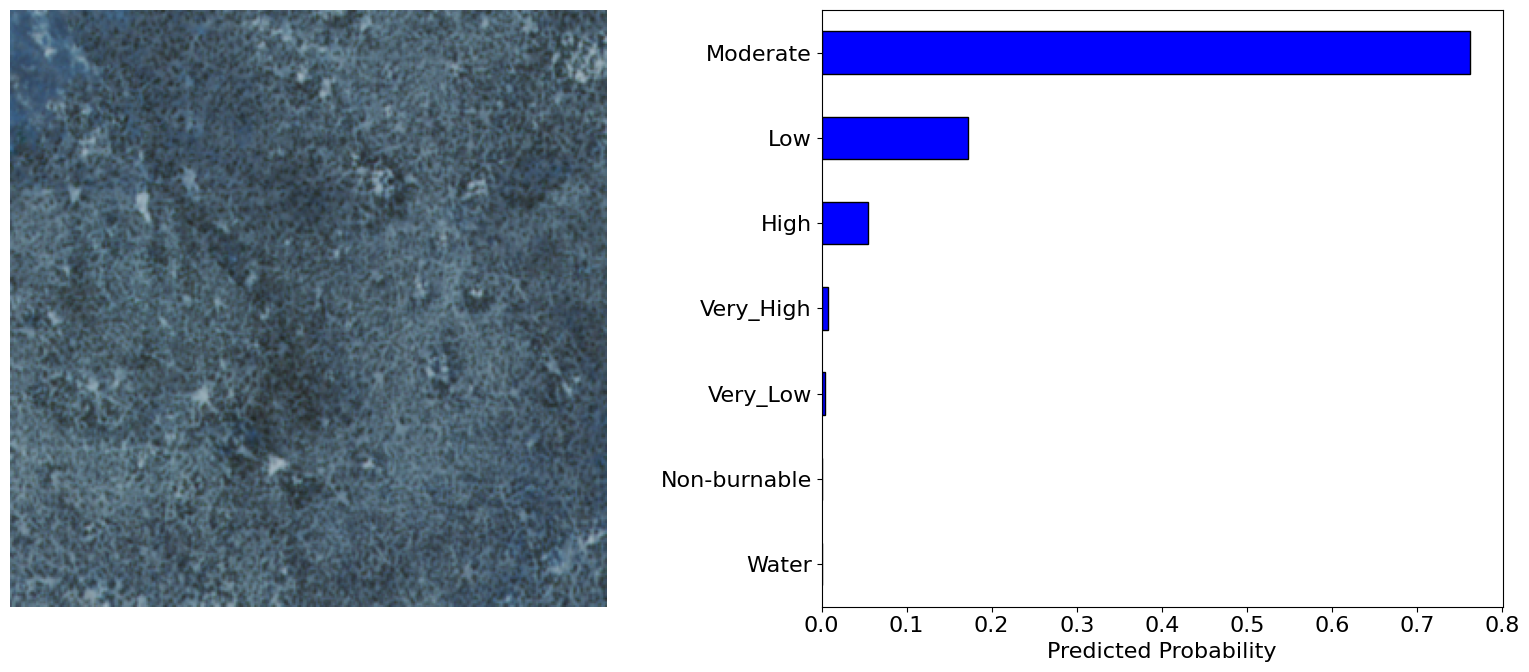

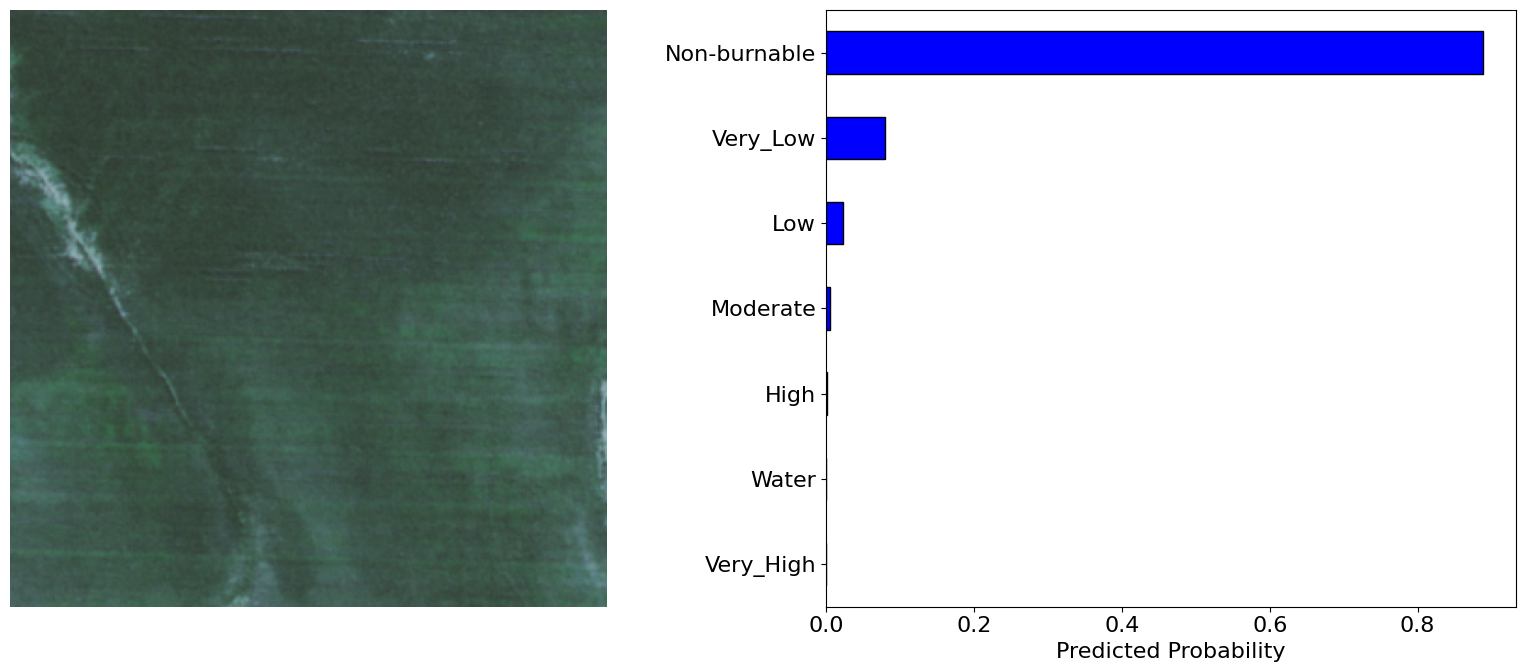

In [ ]:
labels = ["High","Low","Moderate","Non-burnable","Very_High","Very_Low","Water"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/FireRisk/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/FireRisk/val/Low/35502831_2_-123.30644282237_40.2213242337726.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/FireRisk/val/Very_High/35504811_5_-117.120939640739_41.4251599332299.png')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/FireRisk/val/Non-burnable/35510091_6_-99.8525012590982_43.1023776815414.png')
fig = model.predict_image(image, labels, transform)